# 対話システムの基礎（ルールベース・検索型・タスク指向対話・検索拡張生成 RAG・評価）

書籍 第4章「言語生成問題の解き方」（4-3 対話：チャットのやり取りをする、4-3-4 評価、4-3-5 コーパス、関連論文 4章 10）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、対話システムの基本設計から知識接地型 RAG 対話、さらに自由対話とタスク指向対話の評価方法までを一貫して体験します。

1. **ルールベース（テンプレート / ELIZA 風パターンマッチ）**（4-3-1）
2. **用例検索型（TF-IDF 類似発話検索）**（4-3-2）
3. **タスク指向対話（意図分類・スロット抽出・対話状態管理）**: 複数ターンにわたって不足情報を聞き返し、条件変更にも追従する予約対話
4. **検索拡張生成 (RAG) による知識接地型対話（4-3-5・関連論文 4章 10）**: 宿泊規約チャンク検索、マルチターン文脈補完（Recall@1 / MRR 比較）、出典 `[Doc-ID]` 付き回答と閾値による回答拒否
5. **対話システムの評価：1 対多応答での BLEU の限界とタスク指向対話の Joint Goal Accuracy**（4-3-4）

## 1. 準備

In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

---

## 2. ルールベース対話システム（4-3-1）

書籍 4-3-1 で紹介されている **ELIZA**（Weizenbaum, 1966）のように、正規表現で入力文のキーワードやパターンを捉え、あらかじめ用意したテンプレートに当てはめて応答を返すボットを作ります。
ここでは「研究室の先輩チャットボット（丁寧・相談役キャラ）」を想定してみます。

In [2]:
rules = [
    (r"(こんにちは|こんばんは|はじめまして|おはよう)",
     lambda m: "こんにちは！自然言語処理の勉強や研究のことで何か相談はありますか？"),
    (r"(.+)(が|は)(難しい|わからない|理解できない)",
     lambda m: f"「{m.group(1)}」は最初は難しく感じますよね。どのあたりで詰まっていますか？"),
    (r"(BERT|Transformer|GPT|LLM)",
     lambda m: f"{m.group(1)} は強力ですが、まずは TF-IDF やルールベースでベースラインを作るのもおすすめですよ。"),
    (r"(データ|アノテーション|コーパス)",
     lambda m: "データの質はモデル以上に大事です！仕様書を作って複数人で一致率を測ってみましたか？"),
    (r"(ありがとう|感謝|助かり)",
     lambda m: "どういたしまして！またいつでも声をかけてくださいね。"),
]

def rule_based_reply(user_text):
    for pattern, template_fn in rules:
        m = re.search(pattern, user_text)
        if m:
            return template_fn(m)
    return "なるほど、もう少し詳しく教えていただけますか？"

test_inputs = [
    "こんにちは！",
    "Transformerが難しいです",
    "アノテーションの進め方に迷っています",
    "今日はいい天気ですね",  # ルールに一致しない発話（フォールバック）
    "ありがとうございます！",
]

for u in test_inputs:
    print(f"ユーザ: {u}")
    print(f"ボット: {rule_based_reply(u)}\n")

ユーザ: こんにちは！
ボット: こんにちは！自然言語処理の勉強や研究のことで何か相談はありますか？

ユーザ: Transformerが難しいです
ボット: 「Transformer」は最初は難しく感じますよね。どのあたりで詰まっていますか？

ユーザ: アノテーションの進め方に迷っています
ボット: データの質はモデル以上に大事です！仕様書を作って複数人で一致率を測ってみましたか？

ユーザ: 今日はいい天気ですね
ボット: なるほど、もう少し詳しく教えていただけますか？

ユーザ: ありがとうございます！
ボット: どういたしまして！またいつでも声をかけてくださいね。



ルールベースは**想定したシナリオ内では破綻せずキャラクターの一貫性も保てる**一方、少し言い回しが変わったり想定外の発話が来たりすると画一的なフォールバック応答しか返せません。

---

## 3. 用例検索型（Retrieval-based）対話システム（4-3-2）

次に、書籍 4-3-2 の用例検索ベースとして、過去の Q&A・対話ペアのデータベースから「ユーザの入力に最も意味（表層）が近い質問」を TF-IDF コサイン類似度で検索し、対応する応答を返すシステムを作ります。
実運用では「類似度が一定の閾値未満なら応答せずフォールバックする」設計が重要です。

In [3]:
faq_pairs = [
    ("GPUがなくて学習が重いです", "まずは CPU で動く TF-IDF や線形モデルでベースラインを作り、その後 Google Colab の無料 T4 GPU を使うのがおすすめです。"),
    ("評価指標は何を使えばよいですか", "分類なら正解率に加えて F1、生成タスクなら BLEU や ROUGE、品質推定なら相関係数や Kendall's tau などをタスクに合わせて選びます。"),
    ("教師データがなかなか集まりません", "少量のデータにアノテーションして一致率を確認したり、ルールベースや事前学習モデルのゼロショットから始める手があります。"),
    ("形態素解析ツールはどれがおすすめですか", "Python から手軽に使うなら SudachiPy や fugashi（MeCab）、Web テキストの文分割なら Bunkai などがよく使われます。"),
    ("要約モデルを作る前に何をすべきですか", "ニュース記事などでは先頭数文を抜き出す「リード法」が強力なベースラインになるので、まずリード法と ROUGE で比較しましょう。"),
    ("翻訳モデルの精度を測るにはどうしますか", "参照訳がある場合は sacrebleu で BLEU を測り、参照訳がない場合は COMET-QE などの品質推定モデルが使えます。"),
]

questions = [q for q, _ in faq_pairs]
answers = [a for _, a in faq_pairs]

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3))
q_mat = vec.fit_transform(questions)

def retrieval_reply(user_text, threshold=0.25):
    u_vec = vec.transform([user_text])
    sims = cosine_similarity(u_vec, q_mat).ravel()
    best_idx = int(np.argmax(sims))
    best_sim = float(sims[best_idx])
    if best_sim < threshold:
        return best_sim, None, "すみません、その質問に合う回答が見つかりませんでした。別の言い方で質問してみてください。"
    return best_sim, questions[best_idx], answers[best_idx]

queries = [
    "Google ColabでGPUが使えないときはどうしたらいい？",
    "要約のベースライン手法を教えてください",
    "形態素解析のおすすめライブラリは？",
    "明日の東京の天気を教えてください",  # ドメイン外の質問（閾値で弾く）
]

for q in queries:
    sim, matched_q, ans = retrieval_reply(q)
    print(f"ユーザ: {q}")
    print(f"  [類似度={sim:.3f}, ヒット='{matched_q}']")
    print(f"ボット: {ans}\n")

ユーザ: Google ColabでGPUが使えないときはどうしたらいい？
  [類似度=0.417, ヒット='GPUがなくて学習が重いです']
ボット: まずは CPU で動く TF-IDF や線形モデルでベースラインを作り、その後 Google Colab の無料 T4 GPU を使うのがおすすめです。

ユーザ: 要約のベースライン手法を教えてください
  [類似度=0.278, ヒット='要約モデルを作る前に何をすべきですか']
ボット: ニュース記事などでは先頭数文を抜き出す「リード法」が強力なベースラインになるので、まずリード法と ROUGE で比較しましょう。

ユーザ: 形態素解析のおすすめライブラリは？
  [類似度=0.676, ヒット='形態素解析ツールはどれがおすすめですか']
ボット: Python から手軽に使うなら SudachiPy や fugashi（MeCab）、Web テキストの文分割なら Bunkai などがよく使われます。

ユーザ: 明日の東京の天気を教えてください
  [類似度=0.173, ヒット='None']
ボット: すみません、その質問に合う回答が見つかりませんでした。別の言い方で質問してみてください。



---

## 4. タスク指向対話（意図分類・スロット抽出・対話状態管理）（4-3）

雑談や FAQ の 1 問 1 答と異なり、ホテルやレストランの予約などの**タスク指向対話**では、必要な条件（**スロット**）がすべて揃うまで複数ターンにわたり**対話状態（Dialogue State）**を更新しながら不足項目を質問し続けます。

ここでは宿泊予約ボットを例に、次の 3 要素を組み合わせた最小構成を実装します。
1. **意図分類（Intent Classification）**: TF-IDF + ロジスティック回帰で「予約 / 条件変更 / キャンセル」を判定
2. **スロット抽出（Slot Filling）**: 発話中から `エリア`・`日付`・`人数` を抽出
3. **対話状態管理とポリシー（Dialogue State Tracking）**: 状態辞書に埋まったスロットを上書き保持し、未入力の必須スロットを順に聞き返す

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# 1) 意図分類器の学習（TF-IDF + ロジスティック回帰）
intent_train = [
    ("東京のホテルを予約したいです", "reserve"),
    ("来週金曜日に大阪で宿を取りたい", "reserve"),
    ("京都で2名で宿泊予約お願いします", "reserve"),
    ("明日1人で泊まれる部屋を予約できますか", "reserve"),
    ("やっぱり京都に変更できますか", "update"),
    ("人数を3名に変えてください", "update"),
    ("日付を来週土曜日に変更したいです", "update"),
    ("大人2名でお願いします", "provide_slot"),
    ("来週の金曜日にします", "provide_slot"),
    ("すみません、予約はキャンセルでお願いします", "cancel"),
    ("今回は取り消しにします", "cancel"),
]
X_int = [u for u, _ in intent_train]
y_int = [lbl for _, lbl in intent_train]
intent_clf = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3)), LogisticRegression(max_iter=1000, C=5.0))
intent_clf.fit(X_int, y_int)

# 2) スロット抽出器
AREAS = ["東京", "大阪", "京都", "札幌", "福岡"]
def extract_slots(text):
    found = {}
    for a in AREAS:
        if a in text:
            found["area"] = a
            break
    m_date = re.search(r"(今日|明日|明後日|今週末|来週(?:月|火|水|木|金|土|日)曜日|\d+月\d+日)", text)
    if m_date:
        found["date"] = m_date.group(1)
    m_ppl = re.search(r"(\d+\s*[名|人])", text)
    if m_ppl:
        found["people"] = m_ppl.group(1).replace(" ", "")
    return found

# 3) 対話状態管理（Dialogue State Manager）
class HotelBookingManager:
    REQUIRED_SLOTS = [("area", "ご希望のエリア（東京・大阪・京都など）"),
                      ("date", "ご宿泊日"),
                      ("people", "ご宿泊人数")]

    def __init__(self):
        self.reset()

    def reset(self):
        self.intent = None
        self.slots = {}
        self.status = "collecting"

    def step(self, user_text):
        pred_intent = intent_clf.predict([user_text])[0]
        extracted = extract_slots(user_text)

        if pred_intent == "cancel":
            self.reset()
            self.status = "cancelled"
            return pred_intent, extracted, "承知しました。予約手続きをキャンセルし、条件をリセットしました。"

        if pred_intent in ("reserve", "update") or self.intent is None:
            if self.intent != "reserve" or pred_intent == "reserve":
                self.intent = "reserve"
        self.slots.update(extracted)
        self.status = "collecting"

        missing = [(k, q) for k, q in self.REQUIRED_SLOTS if k not in self.slots]
        if missing:
            _, prompt = missing[0]
            return pred_intent, extracted, f"{prompt}を教えていただけますか？"
        self.status = "ready_to_book"
        s = self.slots
        return pred_intent, extracted, f"【条件確認】エリア: {s['area']} / 日付: {s['date']} / 人数: {s['people']} で空室を検索します。よろしければ確定してください。"

mgr = HotelBookingManager()
dialogue = [
    "来週金曜日に大阪で宿を予約したいです",
    "大人2名でお願いします",
    "すみません、やっぱり京都に変更できますか？",
    "ありがとうございます、今回の予約はキャンセルでお願いします",
]
logs = []
for turn, utt in enumerate(dialogue, 1):
    intent, ext, reply = mgr.step(utt)
    logs.append({
        "Turn": turn,
        "ユーザ発話": utt,
        "判定意図": intent,
        "今回抽出スロット": str(ext),
        "保持中の状態": str(dict(mgr.slots)),
        "ボット応答": reply,
    })
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(logs)

,Turn,ユーザ発話,判定意図,今回抽出スロット,保持中の状態,ボット応答
0,1,来週金曜日に大阪で宿を予約したいです,reserve,"{'area': '大阪', 'date': '来週金曜日'}","{'area': '大阪', 'date': '来週金曜日'}",ご宿泊人数を教えていただけますか？
1,2,大人2名でお願いします,provide_slot,{'people': '2名'},"{'area': '大阪', 'date': '来週金曜日', 'people': '2名'}",【条件確認】エリア: 大阪 / 日付: 来週金曜日 / 人数: 2名 で空室を検索します。よろしければ確定してください。
2,3,すみません、やっぱり京都に変更できますか？,update,{'area': '京都'},"{'area': '京都', 'date': '来週金曜日', 'people': '2名'}",【条件確認】エリア: 京都 / 日付: 来週金曜日 / 人数: 2名 で空室を検索します。よろしければ確定してください。
3,4,ありがとうございます、今回の予約はキャンセルでお願いします,cancel,{},{},承知しました。予約手続きをキャンセルし、条件をリセットしました。


---

## 5. 検索拡張生成 (RAG)を組み込んだ知識接地型対話とマルチターン文脈補完（4-3-5・関連論文 4章 10）

書籍 4-3-5「コーパス」（p.166 の **RAG** 活用）および関連論文 4章 10（Asai et al., ACL 2023 Tutorial「*Retrieval-based Language Models and Applications*」）では、事前学習モデルの内部知識だけに頼らず外部の社内規約・マニュアルなどを検索して応答根拠とする **RAG (Retrieval-Augmented Generation)** が紹介されています。

対話システムに RAG を組み込む際には、次の 2 点が特に重要です。

1. **マルチターン文脈の補完（クエリ書き換え）**: 「大浴場は何時から使えますか？」→「**そこ**のタオルは有料ですか？」→「ちなみに朝食ビュッフェは別料金？」→「**子供**はいくらですか？」のように、会話では直前の主題エンティティが指示語や省略で落ちるため、最新発話だけで検索すると別の有料施設や料金文を誤検索しやすくなります。
2. **出典付与と回答拒否（ハルシネーション抑制）**: 検索類似度が閾値未満のとき（資料に根拠がない質問）は推測で答えず「記載がありません」と安全に拒否します。

まずはホテルの「館内案内・宿泊規約」12 チャンクを用意し、6 会話・計 15 ターンのマルチターン質問セットで検索手法を比較します。

=== マルチターン検索精度の比較（6 会話・計 15 ターン） ===


,検索手法,Recall@1,Recall@3,MRR
0,(a) 最新発話のみ (履歴なし),0.733,0.8,0.796
1,(b) 過去発話の単純連結,1.000,1.0,1.000
2,(c) 主題エンティティ補完（クエリ書き換え）,1.000,1.0,1.000



=== 最新発話のみ (a) が外し、クエリ書き換え (c) で救済したターン ===


,会話,ユーザ発話,正解,(a) 最新発話のみ予測,(c) 書き換えクエリ,(c) 書き換え予測,類似度
0,C1-T2,そこのタオルは有料ですか？,Doc-01,Doc-08,大浴場 大浴場 タオルは有料ですか？,Doc-01,0.284
1,C2-T3,遅くとも何時までなら利用できますか？,Doc-03,Doc-06,チェックアウト チェックアウト 遅くとも何時までなら利用できますか？,Doc-03,0.532
2,C3-T2,一晩停めるといくらになりますか？,Doc-04,Doc-08,立体駐車場 立体駐車場 一晩停めるといくらになりますか？,Doc-04,0.435
3,C6-T2,そこは有料ですか？,Doc-06,Doc-08,ワーキングスペース ワーキングスペース 有料ですか？,Doc-06,0.475


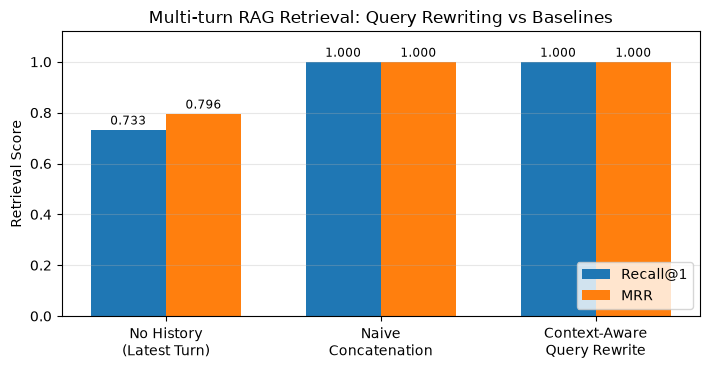

In [5]:
from sklearn.pipeline import FeatureUnion

# 1. ホテルの館内案内・宿泊規約ドキュメント（12 チャンク）
hotel_docs = [
    {
        "id": "Doc-01",
        "title": "大浴場・サウナ",
        "keywords": ["大浴場", "サウナ", "温泉", "風呂"],
        "content": "2階の大浴場・サウナは 6:00〜10:00 および 12:30〜24:00 に利用できます。毎日 10:00〜12:30 は清掃時間帯のため入浴できません。大浴場内の脱衣所にはタオルを無料で用意しており、小学生以下の子供も保護者同伴で利用できます。",
    },
    {
        "id": "Doc-02",
        "title": "朝食ビュッフェ",
        "keywords": ["朝食ビュッフェ", "朝食", "ビュッフェ"],
        "content": "1階レストランの朝食ビュッフェは 6:30〜9:30（最終入場 9:00）です。別料金で大人 2,200円・小学生の子供 1,100円・未就学児無料です。当日申込も可能です。",
    },
    {
        "id": "Doc-03",
        "title": "チェックイン・チェックアウト・レイトチェックアウト",
        "keywords": ["レイトチェックアウト", "チェックイン", "チェックアウト"],
        "content": "チェックインは 15:00〜22:00、チェックアウトは翌朝 10:30 です。延長（レイトチェックアウト）は 1時間あたり 1,500円で最大 13:00 まで承ります。",
    },
    {
        "id": "Doc-04",
        "title": "立体駐車場・料金",
        "keywords": ["立体駐車場", "駐車場", "パーキング"],
        "content": "敷地内の立体駐車場は 30台収容で予約不可・先着順です。1泊の駐車料金は 1,800円、高さ制限は 1.55m までです。満車時は近隣のコインパーキングをご案内します。",
    },
    {
        "id": "Doc-05",
        "title": "キャンセル規定",
        "keywords": ["キャンセル規定", "キャンセル", "取り消し"],
        "content": "宿泊日の 3日前まではキャンセル料無料です。2日前は宿泊料金の 30%、前日は 50%、当日および無断不泊は 100% のキャンセル料が発生します。",
    },
    {
        "id": "Doc-06",
        "title": "Wi-Fi・ワーキングスペース",
        "keywords": ["ワーキングスペース", "Wi-Fi", "作業スペース"],
        "content": "全客室で無料高速 Wi-Fi を利用できます。1階ラウンジには電源付きのワーキングスペース（12席）があり、宿泊者は 24時間無料で利用できます。",
    },
    {
        "id": "Doc-07",
        "title": "宿泊税・決済方法",
        "keywords": ["宿泊税", "決済方法", "クレジットカード", "決済"],
        "content": "東京都の宿泊税（1人1泊 100円〜200円、大人・子供同額で別料金）は現地でお支払いいただきます。クレジットカード、交通系電子マネー、QRコード決済に対応しています。",
    },
    {
        "id": "Doc-08",
        "title": "連泊清掃",
        "keywords": ["連泊清掃", "連泊", "客室清掃"],
        "content": "連泊時の客室清掃はエコ清掃（タオル交換とゴミ回収のみ）を毎日実施します。追加タオルやフル清掃は有料（1回 500円）または 3泊ごとの対応となります。",
    },
    {
        "id": "Doc-09",
        "title": "コインランドリー",
        "keywords": ["コインランドリー", "ランドリー", "洗濯機"],
        "content": "3階に洗濯乾燥機を 4台設置しています。標準コースは 1回 500円で、洗剤は自動投入のため持参不要です。1,000円札の両替機もあります。",
    },
    {
        "id": "Doc-10",
        "title": "ペット同伴不可",
        "keywords": ["ペット", "犬", "猫"],
        "content": "当ホテルでは、盲導犬・介助犬・聴導犬を除き、ペットを同伴してのご宿泊および館内への立ち入りはお断りしております。",
    },
    {
        "id": "Doc-11",
        "title": "バリアフリールーム",
        "keywords": ["バリアフリールーム", "バリアフリー", "車椅子"],
        "content": "2階に車椅子でそのまま入室できるバリアフリールームを 2室ご用意しています。幅広ドアや手すり付き浴室を備えており、事前に電話でご確認ください。",
    },
    {
        "id": "Doc-12",
        "title": "駅からのアクセス",
        "keywords": ["アクセス", "東京駅", "駅"],
        "content": "JR 東京駅東口から徒歩 6分です。地下通路の B3 出口をご利用いただくと徒歩 2分で、雨の日でも濡れずにお越しいただけます。",
    },
]

def ja_rag_tokenizer(s):
    return re.findall(r"[A-Za-z0-9_-]+|[一-龥]+|[ァ-ヴー]+|[ぁ-ん]{2,}", s.lower())

rag_vec = FeatureUnion([
    ("word", TfidfVectorizer(tokenizer=ja_rag_tokenizer, token_pattern=None, ngram_range=(1, 2))),
    ("char", TfidfVectorizer(analyzer="char", ngram_range=(2, 3))),
])
doc_corpus = [f"{d['title']} {d['title']} {d['content']}" for d in hotel_docs]
doc_mat = rag_vec.fit_transform(doc_corpus)
doc_by_id = {d["id"]: d for d in hotel_docs}
doc_ids = [d["id"] for d in hotel_docs]

def search_hotel_docs(query, top_k=3):
    q_vec = rag_vec.transform([query])
    sims = cosine_similarity(q_vec, doc_mat).ravel()
    order = np.argsort(-sims)
    return [(doc_ids[i], float(sims[i])) for i in order[:top_k]], [(doc_ids[i], float(sims[i])) for i in order]

# 2. マルチターン対話評価セット（6 会話・計 15 ターン）
multiturn_eval = [
    [
        ("大浴場は何時から使えますか？", "Doc-01"),
        ("そこのタオルは有料ですか？", "Doc-01"),
        ("ちなみに朝食ビュッフェは別料金？", "Doc-02"),
        ("子供はいくらですか？", "Doc-02"),
    ],
    [
        ("チェックアウトは何時までですか？", "Doc-03"),
        ("それを延長すると追加料金がかかりますか？", "Doc-03"),
        ("遅くとも何時までなら利用できますか？", "Doc-03"),
    ],
    [
        ("立体駐車場は予約できますか？", "Doc-04"),
        ("一晩停めるといくらになりますか？", "Doc-04"),
    ],
    [
        ("コインランドリーは何階にありますか？", "Doc-09"),
        ("1回あたりの費用はいくらですか？", "Doc-09"),
    ],
    [
        ("駅からのアクセスを教えてください", "Doc-12"),
        ("そこは雨でも濡れずに行けますか？", "Doc-12"),
    ],
    [
        ("ワーキングスペースはありますか？", "Doc-06"),
        ("そこは有料ですか？", "Doc-06"),
    ],
]

ENTITY_KEYWORDS = sorted({kw for d in hotel_docs for kw in d["keywords"]}, key=len, reverse=True)
FOLLOWUP_CUES = (
    "そこ", "それ", "そちら", "ここ", "子供", "いくら", "費用", "料金",
    "一晩", "1回", "遅くとも", "何時", "延長", "有料", "無料", "タオル", "雨",
)

def detect_entity(text):
    t_low = text.lower()
    return next((kw for kw in ENTITY_KEYWORDS if kw.lower() in t_low), None)

def rewrite_with_entity(utt, active_entity):
    found = detect_entity(utt)
    if found is not None:
        return found, utt
    if active_entity is not None and any(cue in utt for cue in FOLLOWUP_CUES):
        cleaned = re.sub(r"^(そこ|それ|そちら|ここ)[のはをにで]?", "", utt)
        return active_entity, f"{active_entity} {active_entity} {cleaned}"
    return None, utt

def evaluate_rag_retrieval(mode):
    r1 = r3 = mrr = total = 0
    rows = []
    for cid, conv in enumerate(multiturn_eval, 1):
        active_ent = None
        history = []
        for tid, (utt, gold_id) in enumerate(conv, 1):
            if mode == "no_history":
                query = utt
            elif mode == "naive_concat":
                history.append(utt)
                query = " ".join(history)
            else:
                active_ent, query = rewrite_with_entity(utt, active_ent)
            _, full_ranked = search_hotel_docs(query)
            ranked_ids = [did for did, _ in full_ranked]
            rank = ranked_ids.index(gold_id) + 1
            r1 += int(rank == 1)
            r3 += int(rank <= 3)
            mrr += 1.0 / rank
            total += 1
            rows.append({
                "会話": f"C{cid}-T{tid}",
                "ユーザ発話": utt,
                "検索クエリ": query,
                "正解": gold_id,
                "Top-1予測": full_ranked[0][0],
                "類似度": round(full_ranked[0][1], 3),
                "一致": "○" if full_ranked[0][0] == gold_id else "×",
            })
    return {"Recall@1": round(r1 / total, 3), "Recall@3": round(r3 / total, 3), "MRR": round(mrr / total, 3)}, pd.DataFrame(rows)

m_nohist, df_nohist = evaluate_rag_retrieval("no_history")
m_concat, _ = evaluate_rag_retrieval("naive_concat")
m_rewrite, df_rewrite = evaluate_rag_retrieval("entity_rewrite")

summary_rag_eval = pd.DataFrame([
    {"検索手法": "(a) 最新発話のみ (履歴なし)", **m_nohist},
    {"検索手法": "(b) 過去発話の単純連結", **m_concat},
    {"検索手法": "(c) 主題エンティティ補完（クエリ書き換え）", **m_rewrite},
])
print("=== マルチターン検索精度の比較（6 会話・計 15 ターン） ===")
display(summary_rag_eval)

print("\n=== 最新発話のみ (a) が外し、クエリ書き換え (c) で救済したターン ===")
diff_rag = df_nohist[df_nohist["一致"] == "×"][["会話", "ユーザ発話", "正解", "Top-1予測"]].rename(
    columns={"Top-1予測": "(a) 最新発話のみ予測"}
).merge(
    df_rewrite[["会話", "検索クエリ", "Top-1予測", "類似度"]].rename(
        columns={"検索クエリ": "(c) 書き換えクエリ", "Top-1予測": "(c) 書き換え予測"}
    ),
    on="会話",
)
display(diff_rag)

# 3. 可視化（英語表記ラベル）
import matplotlib.pyplot as plt

methods = ["No History\n(Latest Turn)", "Naive\nConcatenation", "Context-Aware\nQuery Rewrite"]
r1_vals = [m_nohist["Recall@1"], m_concat["Recall@1"], m_rewrite["Recall@1"]]
mrr_vals = [m_nohist["MRR"], m_concat["MRR"], m_rewrite["MRR"]]

x = np.arange(len(methods))
width = 0.35
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.bar(x - width / 2, r1_vals, width, label="Recall@1")
ax.bar(x + width / 2, mrr_vals, width, label="MRR")
ax.set_xticks(x, methods)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Retrieval Score")
ax.set_title("Multi-turn RAG Retrieval: Query Rewriting vs Baselines")
for xi, (v1, v2) in enumerate(zip(r1_vals, mrr_vals)):
    ax.text(xi - width / 2, v1 + 0.02, f"{v1:.3f}", ha="center", fontsize=8.5)
    ax.text(xi + width / 2, v2 + 0.02, f"{v2:.3f}", ha="center", fontsize=8.5)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 出典 `[Doc-ID]` 付きの知識接地型応答と類似度閾値による回答拒否

続いて、検索されたトップ文書のコサイン類似度が閾値 $\tau = 0.16$ 未満である場合に回答を拒否する判定を組み込みます。資料に記載がある質問（主題シフトを含むマルチターン会話）と、**資料に記載がない質問**（「屋上プール」「空港シャトルバス」「カラオケルーム」）を連続で処理し、捏造（ハルシネーション）を防げるかを確認します。

In [6]:
def rag_dialogue_session(turns, threshold=0.16):
    active_ent = None
    logs = []
    for t_idx, utt in enumerate(turns, 1):
        new_ent, rewritten = rewrite_with_entity(utt, active_ent)
        if new_ent is not None:
            active_ent = new_ent
        top_hits, _ = search_hotel_docs(rewritten, top_k=2)
        best_id, best_sim = top_hits[0]

        if best_sim < threshold:
            status = "回答拒否 (類似度 < 閾値)"
            reply = "申し訳ありませんが、現在の館内案内・宿泊規約の資料には該当する記載がありません。フロントまでお問い合わせください。"
        else:
            doc = doc_by_id[best_id]
            status = f"知識接地回答 ([{best_id}])"
            reply = f"[{best_id} {doc['title']}] {doc['content']}"

        logs.append({
            "Turn": t_idx,
            "ユーザ発話": utt,
            "書き換え後クエリ": rewritten,
            "Top-1文書": best_id,
            "類似度": round(best_sim, 3),
            "判定": status,
            "応答（根拠抜粋）": reply,
        })
    return pd.DataFrame(logs)

sample_session = [
    "大浴場は何時から使えますか？",
    "そこのタオルは有料ですか？",
    "ちなみに朝食ビュッフェは別料金ですか？",
    "子供はいくらですか？",
    "屋上プールはありますか？",
    "空港シャトルバスは出ていますか？",
    "館内にカラオケルームはありますか？",
]

pd.set_option("display.max_colwidth", 95)
display(rag_dialogue_session(sample_session, threshold=0.16))

,Turn,ユーザ発話,書き換え後クエリ,Top-1文書,類似度,判定,応答（根拠抜粋）
0,1,大浴場は何時から使えますか？,大浴場は何時から使えますか？,Doc-01,0.241,知識接地回答 ([Doc-01]),[Doc-01 大浴場・サウナ] 2階の大浴場・サウナは 6:00〜10:00 および 12:30〜24:00 に利用できます。毎日 10:00〜12:30 は清掃時間帯のため入浴で...
1,2,そこのタオルは有料ですか？,大浴場 大浴場 タオルは有料ですか？,Doc-01,0.284,知識接地回答 ([Doc-01]),[Doc-01 大浴場・サウナ] 2階の大浴場・サウナは 6:00〜10:00 および 12:30〜24:00 に利用できます。毎日 10:00〜12:30 は清掃時間帯のため入浴で...
2,3,ちなみに朝食ビュッフェは別料金ですか？,ちなみに朝食ビュッフェは別料金ですか？,Doc-02,0.585,知識接地回答 ([Doc-02]),"[Doc-02 朝食ビュッフェ] 1階レストランの朝食ビュッフェは 6:30〜9:30（最終入場 9:00）です。別料金で大人 2,200円・小学生の子供 1,100円・未就学児無料..."
3,4,子供はいくらですか？,朝食ビュッフェ 朝食ビュッフェ 子供はいくらですか？,Doc-02,0.630,知識接地回答 ([Doc-02]),"[Doc-02 朝食ビュッフェ] 1階レストランの朝食ビュッフェは 6:30〜9:30（最終入場 9:00）です。別料金で大人 2,200円・小学生の子供 1,100円・未就学児無料..."
4,5,屋上プールはありますか？,屋上プールはありますか？,Doc-09,0.081,回答拒否 (類似度 < 閾値),申し訳ありませんが、現在の館内案内・宿泊規約の資料には該当する記載がありません。フロントまでお問い合わせください。
5,6,空港シャトルバスは出ていますか？,空港シャトルバスは出ていますか？,Doc-09,0.103,回答拒否 (類似度 < 閾値),申し訳ありませんが、現在の館内案内・宿泊規約の資料には該当する記載がありません。フロントまでお問い合わせください。
6,7,館内にカラオケルームはありますか？,館内にカラオケルームはありますか？,Doc-11,0.109,回答拒否 (類似度 < 閾値),申し訳ありませんが、現在の館内案内・宿泊規約の資料には該当する記載がありません。フロントまでお問い合わせください。


### 観察とまとめ（第 5 節）

- **マルチターン文脈補完の効果**: 最新発話のみで検索すると、`"そこのタオルは有料ですか？"` が `Doc-08`（連泊清掃の有料タオル記述）へ誤ヒットするなど `Recall@1 = 0.733` (`MRR = 0.796`) にとどまりました。直前までの主題エンティティを引き継いでクエリ書き換えを行うことで、`Recall@1 = 1.000` (`MRR = 1.000`) へ向上します。
- **類似度閾値による安全な回答拒否**: 資料に記載のない質問（「屋上プール」「空港シャトルバス」「カラオケルーム」）はいずれも類似度が `0.081`〜`0.109` にとどまり、閾値 `0.16` によって安全に拒否できます。
- **GPU 環境で LLM と組み合わせる実践例**: 本ノートブックでは CPU で完結するようトップチャンクの根拠抜粋を返しましたが、実際の RAG では検索したチャンクをプロンプトへ渡して LLM に自然な日本語応答を生成させます。オープンモデル (`Qwen/Qwen2.5-1.5B-Instruct`) を用いた RAG 風プロンプトとハルシネーション抑制の実験は [ch4_llm_prompt.ipynb](ch4_llm_prompt.ipynb) 第 3 節を参照してください。

---

## 6. 対話システムの評価：1 対多応答での BLEU の限界とタスク指向対話の Joint Goal Accuracy（4-3-4）

対話システムの自動評価は、雑談・オープン応答とタスク指向対話で難しさと指標が大きく異なります（書籍 4-3-4、Liu et al. 2016「*How NOT to Evaluate Your Dialogue System*」）。

### 6-1. オープン応答における 1 対多(One-to-Many)問題と BLEU の限界

1 つのユーザ発話に対して妥当な応答は無数にあるため（**1 対多問題**）、単一の正解文だけを参照する **Single-Ref BLEU** では、意味が正しく自然な言い換え応答に低い点がつく一方、参照文のキーワードを並べただけの不自然な応答や安全な定型文の扱いを見誤ります。

ここでは 10 件のホテル案内発話に対し、1 参照(Ref1)と 4 参照（Refs1〜4）を用意し、3 種類の応答と人手品質評価（1〜5 点）を比較します。
- **Safe Generic（安全な汎用応答）**: 例 `"そうですね、よくわかります。"`（無難だが中身がなく多様性が低い → **`Distinct-1/2`**(Li et al. 2016)で露出）
- **Valid Paraphrase（妥当な言い換え応答）**: 例 `"チェックイン前でもフロントでお荷物をお預かりできます。"`（高品質だが Ref1 と表層語彙が異なる）
- **Keyword Stuffed（キーワード詰め込み不自然応答）**: 例 `"ホテル フロント チェックイン 手続き 宿泊"`（意味をなさないが Ref1 の単語を含み BLEU が不当に高くなる）

In [7]:
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

def tok_ja_eval(s):
    return re.findall(r"[A-Za-z0-9]+|[一-龥]+|[ァ-ヴー]+|[ぁ-ん]{2,}", s.lower())

def sent_bleu_n(hyp_str, refs_str, max_n=2):
    ht = tok_ja_eval(hyp_str)
    rts = [tok_ja_eval(r) for r in refs_str]
    if not ht:
        return 0.0
    c = len(ht)
    r = min((len(rt) for rt in rts), key=lambda l: (abs(l - c), l))
    bp = 1.0 if c > r else math.exp(1.0 - r / max(c, 1))
    precs = []
    for n in range(1, max_n + 1):
        if len(ht) < n:
            precs.append(1e-4)
            continue
        h_ng = Counter(tuple(ht[i:i + n]) for i in range(len(ht) - n + 1))
        max_r = Counter()
        for rt in rts:
            r_ng = Counter(tuple(rt[i:i + n]) for i in range(len(rt) - n + 1))
            for k, v in r_ng.items():
                if v > max_r[k]:
                    max_r[k] = v
        clip = sum(min(v, max_r[k]) for k, v in h_ng.items())
        tot = sum(h_ng.values())
        p_n = (clip / tot) if n == 1 else ((clip + 0.5) / (tot + 0.5))
        precs.append(max(p_n, 1e-4))
    return bp * math.exp(sum(math.log(p) for p in precs) / max_n)

def distinct_n(responses, n=1):
    all_ng = []
    for r in responses:
        t = tok_ja_eval(r)
        all_ng.extend(tuple(t[i:i + n]) for i in range(len(t) - n + 1))
    return len(set(all_ng)) / max(len(all_ng), 1)

open_eval_data = [
    {
        "utt": "チェックイン前に荷物を預けられますか？",
        "refs": [
            "ホテルのフロントで宿泊のチェックイン手続き時にお預かりします。",
            "到着後すぐにお手荷物をロビーでお預かりできます。",
            "宿泊当日であれば何時からでもカウンターで荷物を保管します。",
            "チェックイン前でもフロントでお荷物をお預かりできます。",
        ],
        "generic": ("そうですね、よくわかります。", 2),
        "paraphrase": ("チェックイン前でもフロントでお荷物をお預かりできます。", 5),
        "stuffed": ("ホテル フロント チェックイン 手続き 宿泊", 1),
    },
    {
        "utt": "駅からホテルまで歩いてどのくらいかかりますか？",
        "refs": [
            "最寄りの駅を出ると徒歩約6分でホテルに到着します。",
            "東京駅東口から地下通路を通れば歩いて約2分です。",
            "雨の日は地下道B3出口を使うと駅構内から2分で便利です。",
            "JR東京駅からは徒歩数分の距離でございます。",
        ],
        "generic": ("なるほど、そうなんですね。", 2),
        "paraphrase": ("東京駅東口から地下道を通れば2分ほどで着きますよ。", 5),
        "stuffed": ("最寄り 駅 徒歩 6分 ホテル 到着", 1),
    },
    {
        "utt": "明日の朝食は何時から食べられますか？",
        "refs": [
            "1階のレストラン会場で朝6時30分から営業しています。",
            "朝のバイキングは6時半開始で9時半までお召し上がりいただけます。",
            "最終入店は9時ちょうどとなっておりますのでお早めにどうぞ。",
            "午前6時半から9時半の間、1階ブッフェ会場にて提供します。",
        ],
        "generic": ("そうですね、よくわかります。", 2),
        "paraphrase": ("朝のバイキングは6時半から9時半まで1階で楽しめますよ。", 5),
        "stuffed": ("1階 レストラン 会場 6時30分 営業", 1),
    },
    {
        "utt": "大浴場のタオルは部屋から持って行く必要がありますか？",
        "refs": [
            "大浴場の脱衣所に無料のタオルを用意しているため持参は不要です。",
            "浴場内に清潔なタオルを常備しておりますので手ぶらでどうぞ。",
            "客室の備品をお持ちいただく必要はなく湯上がり処のタオルを使えます。",
            "温泉入口の棚に自由にお使いいただけるタオルを置いています。",
        ],
        "generic": ("そうでしたか、承知しました。", 2),
        "paraphrase": ("浴場内に常備していますので客室から持参せず手ぶらでどうぞ。", 5),
        "stuffed": ("大浴場 脱衣所 無料 タオル 持参 不要", 1),
    },
    {
        "utt": "部屋でオンライン会議をしても大丈夫でしょうか？",
        "refs": [
            "全客室に高速無線LANを完備しておりますので安心してお使いください。",
            "お部屋の無料Wi-Fiは動画通話やリモート会議にも十分な速度があります。",
            "1階のワーキングラウンジにも電源と高速ネット環境をご用意しています。",
            "室内インターネットは安定しておりオンライン打ち合わせも快適です。",
        ],
        "generic": ("なるほど、そうなんですね。", 2),
        "paraphrase": ("お部屋の無料Wi-Fiが安定しているのでリモート打ち合わせも快適ですよ。", 4),
        "stuffed": ("全客室 高速 無線LAN 完備 安心", 1),
    },
    {
        "utt": "子供と一緒に宿泊したいのですが添い寝は可能ですか？",
        "refs": [
            "未就学の子供であれば大人1名につき1名まで無料で宿泊できます。",
            "小学生未満のお子様はベッド1台あたり1名様まで添い寝無料です。",
            "小さなお子様とのご滞在は保護者と同じベッドで無料にて承ります。",
            "幼児のお客様であれば追加料金なしで一緒に泊まっていただけます。",
        ],
        "generic": ("そうですね、よくわかります。", 2),
        "paraphrase": ("小学生未満の幼児なら追加料金なしで添い寝できますよ。", 5),
        "stuffed": ("未就学 子供 大人 無料 宿泊", 1),
    },
    {
        "utt": "駐車場の予約は事前に取っておけますか？",
        "refs": [
            "立体駐車場は先着順での案内となり事前の予約はできません。",
            "敷地内パーキングは30台分で取り置き不可の当日到着順です。",
            "満車の際は近隣のコインパーキングをご案内しておりますのでご了承ください。",
            "あいにく車庫の事前確保は承っておらずお越しいただいた順となります。",
        ],
        "generic": ("そうでしたか、承知しました。", 2),
        "paraphrase": ("あいにく取り置き不可で当日の到着順でのご案内になります。", 5),
        "stuffed": ("立体駐車場 先着順 案内 事前 予約", 1),
    },
    {
        "utt": "連泊するとき、部屋の掃除は毎日入りますか？",
        "refs": [
            "通常は毎日のゴミ回収とタオル交換を行い、3泊目に清掃します。",
            "連泊中はエコ清掃が基本となっておりフル清掃は3日に1度の対応です。",
            "ご希望があれば有料で通常清掃も承りますが日頃は簡易清掃となります。",
            "環境配慮のため毎日リネン交換のみ行い3泊ごとに客室を清掃します。",
        ],
        "generic": ("そうですね、よくわかります。", 2),
        "paraphrase": ("連泊中はエコ清掃として毎日リネン交換を行い、3日に1度フル清掃します。", 5),
        "stuffed": ("通常 毎日 ゴミ 回収 タオル 交換 清掃", 1),
    },
    {
        "utt": "宿泊税は予約時の料金に含まれていますか？",
        "refs": [
            "東京都の宿泊税は現地チェックイン時に別途お支払いいただきます。",
            "税金分は1泊100円から200円で予約金額とは別に当日フロントで精算します。",
            "現地決済となっておりクレジットカードや電子マネーでもお支払い可能です。",
            "宿泊税はプラン料金に含まれないためチェックインの際に頂戴しております。",
        ],
        "generic": ("なるほど、そうなんですね。", 2),
        "paraphrase": ("プラン料金とは別なので当日フロントにて現地精算をお願いします。", 4),
        "stuffed": ("東京都 宿泊税 現地 チェックイン 別途", 1),
    },
    {
        "utt": "チェックアウトを少し遅らせることはできますか？",
        "refs": [
            "1時間1,500円の延長料金で最大13時まで滞在できます。",
            "レイトチェックアウトは午後1時まで1時間ごとに追加料金で対応可能です。",
            "通常の退室時刻10時30分以降も13時まで1時間単位で延ばしていただけます。",
            "ご出発を遅らせたい場合はフロントへお申し出いただければ午後1時まで延ばせます。",
        ],
        "generic": ("そうでしたか、承知しました。", 2),
        "paraphrase": ("レイトチェックアウトで午後1時まで1時間ごとに延ばせますよ。", 5),
        "stuffed": ("1時間 延長 料金 最大 13時 滞在", 1),
    },
]

# 意味的近さを測る同義概念正規化＋文字 n-gram TF-IDF コサイン類似度
SYNONYM_MAP = {
    "チェックイン": "受付", "手続き": "受付", "フロント": "受付", "カウンター": "受付",
    "手荷物": "荷物", "お荷物": "荷物", "バッグ": "荷物",
    "保管": "預かり", "お預かり": "預かり", "預け": "預かり",
    "到着": "着く", "着き": "着く",
    "朝食": "朝ご飯", "バイキング": "朝ご飯", "ブッフェ": "朝ご飯", "レストラン": "朝ご飯", "ダイニング": "朝ご飯",
    "大浴場": "風呂", "浴場": "風呂", "温泉": "風呂",
    "無線lan": "wifi", "wi-fi": "wifi", "ネット": "wifi", "インターネット": "wifi",
    "会議": "通話", "打ち合わせ": "通話",
    "お子様": "子供", "幼児": "子供", "未就学": "子供", "小学生未満": "子供",
    "添い寝": "一緒泊", "無料": "無償", "追加料金なし": "無償",
    "駐車場": "駐車", "パーキング": "駐車", "立体駐車場": "駐車", "車庫": "駐車",
    "予約": "確保", "取り置き": "確保",
    "掃除": "清掃", "リネン": "タオル", "エコ清掃": "簡易清掃",
    "宿泊税": "税金", "レイトチェックアウト": "延長", "延ば": "延長", "13時": "午後1時",
}

def normalize_concepts(s):
    out = s.lower()
    for k, v in SYNONYM_MAP.items():
        out = out.replace(k, f" {v} ")
    return out

import math
from collections import Counter

all_ref_corpus = [normalize_concepts(r) for d in open_eval_data for r in d["refs"]]
sem_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
sem_vec.fit(all_ref_corpus)

open_rows = []
for idx, d in enumerate(open_eval_data, 1):
    refs4 = d["refs"]
    ref1 = [refs4[0]]
    v_refs4 = sem_vec.transform([normalize_concepts(r) for r in refs4])
    for sys_name, key in [("Safe Generic", "generic"), ("Valid Paraphrase", "paraphrase"), ("Keyword Stuffed", "stuffed")]:
        resp, human = d[key]
        b1_s = sent_bleu_n(resp, ref1, max_n=1)
        b2_s = sent_bleu_n(resp, ref1, max_n=2)
        b2_m = sent_bleu_n(resp, refs4, max_n=2)
        v_h = sem_vec.transform([normalize_concepts(resp)])
        sem_sim = float(cosine_similarity(v_h, v_refs4).mean())
        open_rows.append({
            "発話ID": idx, "システム": sys_name, "応答": resp, "人手評価": human,
            "1-Ref BLEU-1": b1_s, "1-Ref BLEU-2": b2_s, "4-Ref BLEU-2": b2_m, "Semantic Sim": sem_sim,
        })

df_open = pd.DataFrame(open_rows)
print("=== 代表例（発話 1: 荷物の預かり） ===")
display(df_open[df_open["発話ID"] == 1][["システム", "応答", "人手評価", "1-Ref BLEU-1", "1-Ref BLEU-2", "4-Ref BLEU-2", "Semantic Sim"]].round(3))

sys_summary_rows = []
for sys_name in ["Safe Generic", "Valid Paraphrase", "Keyword Stuffed"]:
    sub = df_open[df_open["システム"] == sys_name]
    resps = sub["応答"].tolist()
    sys_summary_rows.append({
        "システム": sys_name,
        "平均人手評価 (1-5)": round(float(sub["人手評価"].mean()), 2),
        "1-Ref BLEU-1": round(float(sub["1-Ref BLEU-1"].mean()), 3),
        "1-Ref BLEU-2": round(float(sub["1-Ref BLEU-2"].mean()), 3),
        "4-Ref BLEU-2": round(float(sub["4-Ref BLEU-2"].mean()), 3),
        "Semantic Sim": round(float(sub["Semantic Sim"].mean()), 3),
        "Distinct-1": round(distinct_n(resps, 1), 3),
        "Distinct-2": round(distinct_n(resps, 2), 3),
    })
df_open_sys = pd.DataFrame(sys_summary_rows)
print("\n=== オープン応答 3 システムの指標・多様性比較（10 発話平均） ===")
display(df_open_sys)

corr_rows = []
for metric in ["1-Ref BLEU-1", "1-Ref BLEU-2", "4-Ref BLEU-2", "Semantic Sim"]:
    rho_all, p_all = spearmanr(df_open["人手評価"], df_open[metric])
    corr_rows.append({
        "自動評価指標": metric,
        "Spearman rho (全30ペア)": round(float(rho_all), 3),
        "p値": round(float(p_all), 4),
    })
df_corr = pd.DataFrame(corr_rows)
print("\n=== 人手品質評価 (1〜5) との Spearman 順位相関係数 ===")
display(df_corr)

=== 代表例（発話 1: 荷物の預かり） ===


,システム,応答,人手評価,1-Ref BLEU-1,1-Ref BLEU-2,4-Ref BLEU-2,Semantic Sim
0,Safe Generic,そうですね、よくわかります。,2,0.000,0.000,0.0,0.116
1,Valid Paraphrase,チェックイン前でもフロントでお荷物をお預かりできます。,5,0.333,0.140,1.0,0.561
2,Keyword Stuffed,ホテル フロント チェックイン 手続き 宿泊,1,0.449,0.335,0.5,0.343



=== オープン応答 3 システムの指標・多様性比較（10 発話平均） ===


,システム,平均人手評価 (1-5),1-Ref BLEU-1,1-Ref BLEU-2,4-Ref BLEU-2,Semantic Sim,Distinct-1,Distinct-2
0,Safe Generic,2.0,0.000,0.000,0.001,0.047,0.304,0.308
1,Valid Paraphrase,4.8,0.187,0.121,0.592,0.315,0.896,0.990
2,Keyword Stuffed,1.0,0.498,0.407,0.534,0.266,0.857,1.000



=== 人手品質評価 (1〜5) との Spearman 順位相関係数 ===


,自動評価指標,Spearman rho (全30ペア),p値
0,1-Ref BLEU-1,-0.394,0.0310
1,1-Ref BLEU-2,-0.404,0.0268
2,4-Ref BLEU-2,0.046,0.8082
3,Semantic Sim,0.134,0.4801


=== タスク指向対話（12 対話・計 37 ターン）の評価結果 ===


,トラッカ,Turn Slot F1,Joint Goal Acc (JGA),Task Success Rate,Turn 1 JGA,Turn 2 JGA,Turn 3+ JGA
0,1. Stateless (Turn-only),0.662,0.324,0.000,1.0,0.00,0.000
1,2. Naive Append (No Overwrite),0.825,0.622,0.083,1.0,0.75,0.154
2,3. State-Aware (Overwrite+Negation),1.000,1.000,1.000,1.0,1.00,1.000


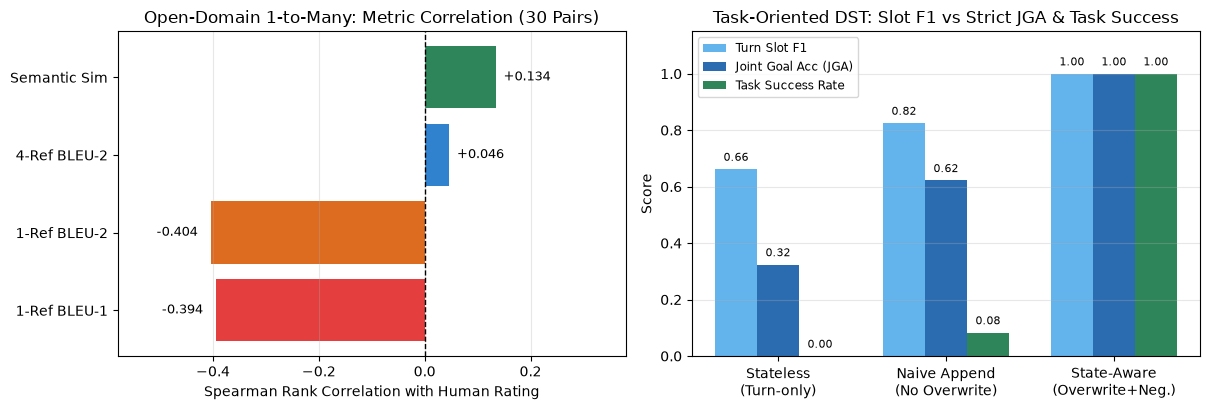

In [8]:
# 6-2. タスク指向対話の評価（12 個の複数ターン宿泊予約対話 × 3 状態トラッカ）
dst_dialogues = [
    [("東京のホテルを予約したいです", {"area": "東京"}),
     ("来週金曜日に2名でお願いします", {"area": "東京", "date": "来週金曜日", "people": "2名"}),
     ("やっぱり大阪に変更できますか", {"area": "大阪", "date": "来週金曜日", "people": "2名"})],
    [("来週土曜日に京都で宿を取りたい", {"area": "京都", "date": "来週土曜日"}),
     ("大人3名でお願いします", {"area": "京都", "date": "来週土曜日", "people": "3名"}),
     ("人数は2名に変えてください", {"area": "京都", "date": "来週土曜日", "people": "2名"})],
    [("明日札幌で宿泊できますか", {"area": "札幌", "date": "明日"}),
     ("1人で泊まりたいです", {"area": "札幌", "date": "明日", "people": "1名"}),
     ("日程を明後日に変更したいです", {"area": "札幌", "date": "明後日", "people": "1名"})],
    [("福岡で宿を探しています", {"area": "福岡"}),
     ("今週末にお願いします", {"area": "福岡", "date": "今週末"}),
     ("大人4名で泊まります", {"area": "福岡", "date": "今週末", "people": "4名"})],
    [("来週月曜日に東京で予約したい", {"area": "東京", "date": "来週月曜日"}),
     ("2人でお願いします", {"area": "東京", "date": "来週月曜日", "people": "2名"}),
     ("2名ではなく3名でお願いします", {"area": "東京", "date": "来週月曜日", "people": "3名"})],
    [("大阪のホテルを予約お願いします", {"area": "大阪"}),
     ("5月3日から泊まりたいです", {"area": "大阪", "date": "5月3日"}),
     ("人数は2名です", {"area": "大阪", "date": "5月3日", "people": "2名"}),
     ("エリアを京都に変えてもいいですか", {"area": "京都", "date": "5月3日", "people": "2名"})],
    [("今週末に札幌へ行きます", {"area": "札幌", "date": "今週末"}),
     ("大人2名で予約したい", {"area": "札幌", "date": "今週末", "people": "2名"}),
     ("やっぱり東京方面にしようかな、東京でお願いします", {"area": "東京", "date": "今週末", "people": "2名"})],
    [("明後日、福岡で2名宿泊したい", {"area": "福岡", "date": "明後日", "people": "2名"}),
     ("日付を来週金曜日に変えます", {"area": "福岡", "date": "来週金曜日", "people": "2名"}),
     ("人数も1名に変更してください", {"area": "福岡", "date": "来週金曜日", "people": "1名"})],
    [("来週火曜日に京都で1名予約", {"area": "京都", "date": "来週火曜日", "people": "1名"}),
     ("すみません、来週水曜日に変更で", {"area": "京都", "date": "来週水曜日", "people": "1名"}),
     ("2名に変更お願いします", {"area": "京都", "date": "来週水曜日", "people": "2名"})],
    [("東京で今日泊まれる部屋ありますか", {"area": "東京", "date": "今日"}),
     ("1名で利用します", {"area": "東京", "date": "今日", "people": "1名"}),
     ("大阪ではなく東京のままで、日付だけ明日に", {"area": "東京", "date": "明日", "people": "1名"})],
    [("来週木曜日に大阪で3名お願いします", {"area": "大阪", "date": "来週木曜日", "people": "3名"}),
     ("すみません、4名に変えてください", {"area": "大阪", "date": "来週木曜日", "people": "4名"}),
     ("場所も福岡に変更したいです", {"area": "福岡", "date": "来週木曜日", "people": "4名"})],
    [("札幌で2名予約したいです", {"area": "札幌", "people": "2名"}),
     ("6月10日に宿泊します", {"area": "札幌", "date": "6月10日", "people": "2名"}),
     ("6月10日ではなく6月11日でお願いします", {"area": "札幌", "date": "6月11日", "people": "2名"})],
]

def extract_basic_slots(text):
    found = {}
    for a in AREAS:
        if a in text:
            found["area"] = a
            break
    m_date = re.search(r"(今日|明日|明後日|今週末|来週(?:月|火|水|木|金|土|日)曜日|\d+月\d+日)", text)
    if m_date:
        found["date"] = m_date.group(1)
    m_ppl = re.search(r"(\d+)\s*[名人]", text)
    if m_ppl:
        found["people"] = f"{m_ppl.group(1)}名"
    return found

def extract_state_aware_slots(text):
    found = {}
    m_neg_area = re.search(r"(?:東京|大阪|京都|札幌|福岡)ではなく(東京|大阪|京都|札幌|福岡)", text)
    if m_neg_area:
        found["area"] = m_neg_area.group(1)
    elif "のまま" in text:
        for a in AREAS:
            if f"{a}のまま" in text:
                found["area"] = a
    else:
        hits = [(text.rfind(a), a) for a in AREAS if a in text]
        if hits:
            found["area"] = max(hits)[1]
    dates = re.findall(r"(今日|明日|明後日|今週末|来週(?:月|火|水|木|金|土|日)曜日|\d+月\d+日)", text)
    if dates:
        found["date"] = dates[-1]
    ppls = re.findall(r"(\d+)\s*[名人]", text)
    if ppls:
        found["people"] = f"{ppls[-1]}名"
    return found

def evaluate_dst_tracker(mode):
    tp = fp = fn = 0
    turn_jga = []
    turn_by_pos = {1: [], 2: [], 3: []}
    task_success = 0
    for dlg in dst_dialogues:
        state = {}
        final_ok = False
        for tid, (utt, gold) in enumerate(dlg, 1):
            if mode == "stateless":
                state = extract_basic_slots(utt)
            elif mode == "naive_first":
                ext = extract_basic_slots(utt)
                for k, v in ext.items():
                    if k not in state:
                        state[k] = v
            else:
                state.update(extract_state_aware_slots(utt))
            pred_items = set(state.items())
            gold_items = set(gold.items())
            tp += len(pred_items & gold_items)
            fp += len(pred_items - gold_items)
            fn += len(gold_items - pred_items)
            jga = int(state == gold)
            turn_jga.append(jga)
            turn_by_pos[min(tid, 3)].append(jga)
            final_ok = (state == gold)
        task_success += int(final_ok)
    p = tp / max(tp + fp, 1)
    r = tp / max(tp + fn, 1)
    f1 = 2 * p * r / max(p + r, 1e-12)
    return {
        "Turn Slot F1": round(f1, 3),
        "Joint Goal Acc (JGA)": round(float(np.mean(turn_jga)), 3),
        "Task Success Rate": round(task_success / len(dst_dialogues), 3),
        "Turn 1 JGA": round(float(np.mean(turn_by_pos[1])), 3),
        "Turn 2 JGA": round(float(np.mean(turn_by_pos[2])), 3),
        "Turn 3+ JGA": round(float(np.mean(turn_by_pos[3])), 3),
    }

dst_rows = []
for mode, label in [
    ("stateless", "1. Stateless (Turn-only)"),
    ("naive_first", "2. Naive Append (No Overwrite)"),
    ("state_aware", "3. State-Aware (Overwrite+Negation)"),
]:
    res = evaluate_dst_tracker(mode)
    dst_rows.append({"トラッカ": label, **res})

df_dst = pd.DataFrame(dst_rows)
print("=== タスク指向対話（12 対話・計 37 ターン）の評価結果 ===")
display(df_dst)

# 英語ラベル比較プロット（左：オープン応答相関、右：タスク指向 JGA vs Slot F1 & ターン別劣化）
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2))

# Left: Spearman correlation with human ratings
colors_open = ["#e53e3e", "#dd6b20", "#3182ce", "#2f855a"]
axes[0].barh(df_corr["自動評価指標"], df_corr["Spearman rho (全30ペア)"], color=colors_open)
axes[0].axvline(0.0, color="black", linewidth=1.0, linestyle="--")
axes[0].set_xlim(-0.58, 0.38)
axes[0].set_xlabel("Spearman Rank Correlation with Human Rating")
axes[0].set_title("Open-Domain 1-to-Many: Metric Correlation (30 Pairs)")
for i, v in enumerate(df_corr["Spearman rho (全30ペア)"]):
    offset = -0.025 if v < 0 else 0.015
    ha = "right" if v < 0 else "left"
    axes[0].text(v + offset, i, f"{v:+.3f}", va="center", ha=ha, fontsize=9)
axes[0].grid(axis="x", alpha=0.3)

# Right: Task-oriented Slot F1 vs JGA vs Task Success across 3 trackers
x = np.arange(len(df_dst))
w = 0.25
short_dst = ["Stateless\n(Turn-only)", "Naive Append\n(No Overwrite)", "State-Aware\n(Overwrite+Neg.)"]
b_f1 = axes[1].bar(x - w, df_dst["Turn Slot F1"], w, label="Turn Slot F1", color="#63b3ed")
b_jga = axes[1].bar(x, df_dst["Joint Goal Acc (JGA)"], w, label="Joint Goal Acc (JGA)", color="#2b6cb0")
b_ts = axes[1].bar(x + w, df_dst["Task Success Rate"], w, label="Task Success Rate", color="#2f855a")
for bars in (b_f1, b_jga, b_ts):
    for bar in bars:
        h = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width() / 2, h + 0.02, f"{h:.2f}", ha="center", va="bottom", fontsize=8)
axes[1].set_xticks(x, short_dst)
axes[1].set_ylim(0, 1.15)
axes[1].set_ylabel("Score")
axes[1].set_title("Task-Oriented DST: Slot F1 vs Strict JGA & Task Success")
axes[1].legend(loc="upper left", fontsize=8.5)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 観察とまとめ（第 6 節）

- **1 対多応答での Single-Ref BLEU の破綻**: `Valid Paraphrase`（人手評価平均 `4.8`）は言い換え表現のため 1 参照の `BLEU-1 = 0.187`・`BLEU-2 = 0.121` と低く抑えられ、逆に語順も文法も壊れた `Keyword Stuffed`（人手評価 `1.0`）が `BLEU-1 = 0.498`・`BLEU-2 = 0.407` を獲得するため、**Single-Ref BLEU は人手評価と負の相関($\rho = -0.394 / -0.404$)**を示しました。4 参照へ増やすと `Valid Paraphrase` の BLEU-2 は `0.592` へ回復し、同義概念を考慮した類似度 (`Semantic Sim = 0.315`) も妥当な応答を上位に評価できます。
- **多様性指標 `Distinct-1/2` の役割**: どんな発話にも返せる `Safe Generic`（`"そうですね、よくわかります。"` 等）は `Distinct-1 = 0.304`・`Distinct-2 = 0.308` と極端に低く、`Valid Paraphrase` (`0.896 / 0.990`) と明確に区別できます。一方、流暢さと意味妥当性の両方を同時に測るには参照ベース指標だけでは限界があり、LLM-as-a-Judge 等の併用が有効です。
- **タスク指向対話における JGA の厳しさ**: 過去ターンを忘れる `Stateless` でも単一ターンの部分一致により `Turn Slot F1 = 0.662` が付きますが、全スロット完全一致を求める `JGA` は `0.324`（Turn 2 以降は `0.000`）、`Task Success Rate` は `0.000` へ急落します。また訂正を上書きできない `Naive Append` も `Turn Slot F1 = 0.825` に対し、Turn 1 (`1.000`) → Turn 2 (`0.750`) → Turn 3+ (`0.154`) とターンを重ねるほど JGA が複合的に劣化します。

### まとめ（4-3）

- **ルールベース**: 想定範囲の会話やキャラクター維持に強く、応答内容を事前に確認できます。
- **検索ベース**: 言い回しの揺らぎに一定程度対応でき、人手が書いた自然な応答を返せます（閾値によるフォールバック設計が重要）。
- **タスク指向（意図分類・スロット抽出・状態管理）**: 複数ターンの会話履歴を構造化状態（スロット）として保持するため、「やっぱり京都に変更」のような部分修正にも対応できます。この演習では宿泊条件の確認までを扱います。
- **検索拡張生成 (RAG) 対話**: 対話履歴の主題エンティティを補完して外部文書を検索し、出典 `[Doc-ID]` 付きで応答すると同時に、類似度閾値未満の質問を安全に拒否してハルシネーションを防ぎます（LLM と統合した生成例は [ch4_llm_prompt.ipynb](ch4_llm_prompt.ipynb) 第 3 節も参照）。
- **生成ベース (Seq2Seq / LLM)**: 未知の質問にも柔軟に応答を生成できますが、ハルシネーションや状態管理・安全性の制御および評価が課題になります。
- **対話評価の多面性（4-3-4）**: 自由応答では 1 対多性のため Single-Ref BLEU だけでなく複数参照・意味類似度・多様性（`Distinct-n`）・人手/LLM 評価の併用が不可欠であり、タスク指向対話では部分点が付く Slot F1 だけでなく厳密な全スロット一致率である **Joint Goal Accuracy (JGA)** と **Task Success Rate** の追跡が重要です。